# Thí nghiệm 02 · Đo tác động của lịch sử với RF và Gradient Boosting

**Câu hỏi.** Khi giữ nguyên giờ train, giờ validation và tham số của mỗi mô hình, ba đặc trưng lịch sử làm thay đổi RMSE bao nhiêu?

```text
CSV gốc → gộp theo giờ → chia theo thời gian
    → học điền thiếu từ train → tạo đặc trưng quá khứ
    → lọc chung các giờ đủ lịch sử trong train và validation
    → kiểm tra cùng giờ, cùng mục tiêu → fit từng cặp B/C → chấm validation
```

B dùng thời gian, ngày lễ và thời tiết. C thêm `lag_24h`, `lag_168h` và `mean_24h`. Giả định dự đoán từng giờ khi có thời tiết cùng giờ và các quan sát lưu lượng của những giờ trước. Tập test nằm ngoài lần đánh giá này.

In [1]:
from hashlib import file_digest
import json
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
project = next(path for path in (cwd, *cwd.parents) if (path / "src" / "data.py").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
import sklearn

from src.data import DATA_PATH, fill_missing_weather, load_hourly_splits
from src.evaluation import clip_prediction, regression_metrics
from src.features import CONFIG_B, CONFIG_C, HISTORY_FEATURES, build_features, has_history
from src.models import make_fixed_model

experiment = project / "experiments" / "17-11-2026_Huy_ConfigC" / "02_models_bc"
data_path = DATA_PATH if DATA_PATH.is_file() else project / "files" / "Metro_Interstate_Traffic_Volume.csv.gz"
data_params = {"mask_stuck_temp": False, "complete_holidays": False}
features = {"B": list(CONFIG_B), "C": list(CONFIG_C)}
model_specs = {
    "rf": (
        "Random Forest",
        dict(n_estimators=400, max_depth=12, min_samples_leaf=5, max_features=1.0, random_state=42, n_jobs=4),
    ),
    "gb": (
        "Gradient Boosting",
        dict(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=42),
    ),
}

hourly = load_hourly_splits(data_path, **data_params)
raw = {name: hourly[name] for name in ("train", "validation")}
feature_tables = build_features(fill_missing_weather(raw))
eligible = {
    name: frame.loc[has_history(frame)].set_index("date_time", verify_integrity=True)
    for name, frame in feature_tables.items()
}

if features["C"] != features["B"] + list(HISTORY_FEATURES):
    raise ValueError("Config C phải có đủ các cột B, rồi thêm các cột lịch sử.")

for name, frame in eligible.items():
    if not frame.index.is_monotonic_increasing or frame.index.hasnans:
        raise ValueError(f"Giờ {name} phải đầy đủ và tăng dần.")
    inputs_b = frame[features["B"]]
    inputs_c = frame[features["C"]]
    pd.testing.assert_index_equal(inputs_b.index, inputs_c.index, exact=True)
    pd.testing.assert_frame_equal(inputs_b, inputs_c[features["B"]])
    expected = raw[name].set_index("date_time", verify_integrity=True).loc[frame.index, "traffic_volume"]
    pd.testing.assert_series_equal(expected, frame["traffic_volume"])
    if inputs_c.isna().any().any():
        raise ValueError(f"Còn giá trị thiếu trong nhóm đặc trưng {name}.")

train, validation = eligible["train"], eligible["validation"]
if train.index.max() >= validation.index.min():
    raise ValueError("Train phải kết thúc trước validation.")

counts = pd.DataFrame([
    {
        "split": name,
        "n_hourly": len(raw[name]),
        "n_eligible": len(frame),
        "n_excluded": len(raw[name]) - len(frame),
        "first_eligible": frame.index.min(),
        "last_eligible": frame.index.max(),
    }
    for name, frame in eligible.items()
])
display(counts)

notebook cell 1:42: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 1:42: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 1:56: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
notebook cell 1:56: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.


,split,n_hourly,n_eligible,n_excluded,first_eligible,last_eligible
0,train,28402,22503,5899,2012-10-09 09:00:00,2017-05-10 04:00:00
1,validation,6086,6050,36,2017-05-10 05:00:00,2018-01-19 14:00:00


Các tham số RF lấy từ [thí nghiệm ngày 17/11](../../17-11-2026_Huy_Xulydulieu/RandomForest_AB_Huy.ipynb). GB dùng tham số đã lưu của Config B trong [V3](../../../notebooks/separate/V_3.ipynb). Cả hai bộ tham số giữ cố định trong từng cặp B/C.

In [2]:
predictions = validation[["traffic_volume", "is_rush_hour"]].copy()
metric_rows = []
peak_rows = []
for model_key, (model_name, params) in model_specs.items():
    for config, columns in features.items():
        model = make_fixed_model(model_name, params)
        model.fit(train[columns], train["traffic_volume"])
        prediction_key = f"{model_key}_{config.lower()}"
        predictions[prediction_key] = clip_prediction(model.predict(validation[columns]))
        metrics = regression_metrics(predictions["traffic_volume"], predictions[prediction_key])
        metric_rows.append({"model": model_name, "config": config, "n_validation": len(predictions), **metrics})
        for hour_group, is_rush_hour in (("peak", 1), ("non_peak", 0)):
            subset = predictions.loc[predictions["is_rush_hour"].eq(is_rush_hour)]
            sliced = regression_metrics(subset["traffic_volume"], subset[prediction_key])
            peak_rows.append({
                "model": model_name, "config": config, "hour_group": hour_group,
                "n_hours": len(subset), **sliced,
            })

metrics = pd.DataFrame(metric_rows)
slices = pd.DataFrame(peak_rows)
comparison = metrics.pivot(index="model", columns="config", values="RMSE")
comparison = comparison.rename(columns={"B": "RMSE_B", "C": "RMSE_C"})
comparison["RMSE_reduction_B_minus_C"] = comparison["RMSE_B"] - comparison["RMSE_C"]

outputs = experiment / "outputs"
outputs.mkdir(exist_ok=True)
predictions_path = outputs / "validation_predictions.csv"
pending_predictions = predictions_path.with_suffix(".pending")
predictions.to_csv(pending_predictions)
pending_predictions.replace(predictions_path)
metrics.to_csv(outputs / "validation_metrics.csv", index=False)
slices.to_csv(outputs / "validation_peak_slices.csv", index=False)
comparison.to_csv(outputs / "validation_comparison.csv")
counts.to_csv(outputs / "split_counts.csv", index=False)
with data_path.open("rb") as source:
    data_hash = file_digest(source, "sha256").hexdigest()
run_config = {
    "dataset": data_path.relative_to(project).as_posix(),
    "dataset_sha256": data_hash,
    "data_params": data_params,
    "features": features,
    "eligible_rule": "All three history features are known in both scored and training rows.",
    "evaluation": "hourly validation with earlier observed traffic and same-hour weather available",
    "fixed_params": {name: params for name, params in model_specs.values()},
    "parameter_sources": {
        "Random Forest": "17-11-2026_Huy_Xulydulieu/outputs/run_config.json",
        "Gradient Boosting": "notebooks/separate/V_3.ipynb (saved Config B parameters)",
    },
    "versions": {"pandas": pd.__version__, "scikit_learn": sklearn.__version__},
}
(outputs / "run_config.json").write_text(json.dumps(run_config, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

display(metrics.round(3))
display(comparison.round(3))
display(slices.round(3))

,model,config,n_validation,MAE,RMSE,R2
0,Random Forest,B,6050,254.662,410.006,0.956
1,Random Forest,C,6050,215.191,354.353,0.967
2,Gradient Boosting,B,6050,277.027,422.352,0.954
3,Gradient Boosting,C,6050,229.276,366.125,0.965


config,RMSE_B,RMSE_C,RMSE_reduction_B_minus_C
model,,,
Gradient Boosting,422.352,366.125,56.227
Random Forest,410.006,354.353,55.653


,model,config,hour_group,n_hours,MAE,RMSE,R2
0,Random Forest,B,peak,1080,378.899,580.262,0.601
1,Random Forest,B,non_peak,4970,227.664,362.585,0.956
2,Random Forest,C,peak,1080,303.041,494.344,0.710
3,Random Forest,C,non_peak,4970,196.101,315.829,0.967
4,Gradient Boosting,B,peak,1080,411.941,620.217,0.544
5,Gradient Boosting,B,non_peak,4970,247.710,365.450,0.955
6,Gradient Boosting,C,peak,1080,329.916,532.128,0.664
7,Gradient Boosting,C,non_peak,4970,207.407,318.818,0.966


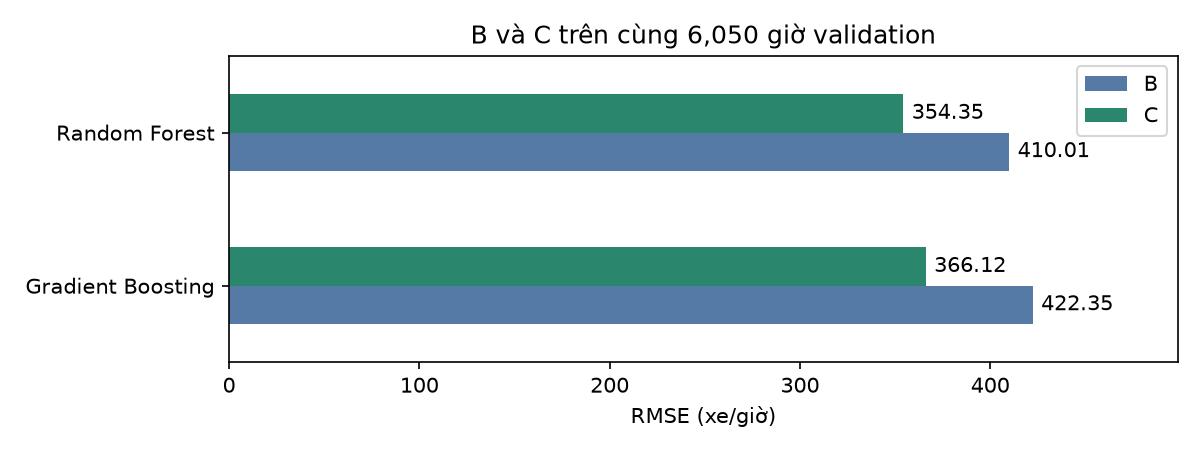

In [3]:
figures = experiment / "figures"
figures.mkdir(exist_ok=True)
figure = figures / "validation_rmse_bc.png"
ax = comparison[["RMSE_B", "RMSE_C"]].plot.barh(color=["#547AA5", "#2A866D"], figsize=(8, 3))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_xlim(0, comparison[["RMSE_B", "RMSE_C"]].max().max() * 1.18)
ax.set_xlabel("RMSE (xe/giờ)")
ax.set_ylabel("")
ax.set_title(f"B và C trên cùng {len(validation):,} giờ validation")
ax.legend(["B", "C"])
ax.figure.tight_layout()
ax.figure.savefig(figure, dpi=150)
plt.close(ax.figure)
display(Image(filename=str(figure)))